## log TRANSFORM ##

**where to use**

suppose you have a right skewed data set so it makes it normall data.

**right skewed** -> whose peak is at left 

**advantage** --> bigger data points comes close at a certain distance like 10,100,1000,10000 to 1,2,3,4 by log base 10

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split , cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

from sklearn.metrics import accuracy_score

import scipy.stats as stats # for qq plots

import warnings
warnings.filterwarnings('ignore')

In [3]:
data = pd.read_csv(r'D:\programming\datasets\train.csv')
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df = pd.read_csv(r'D:\programming\datasets\train.csv' , usecols=['Age' , 'Survived' , 'Fare'])
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [5]:
df['Age'].isnull().sum()

np.int64(177)

In [6]:
df['Age'].mean()

np.float64(29.69911764705882)

In [7]:
df['Age'].fillna(df['Age'].mean() , inplace=True)

## TRAIN_TEST_SPLIT ##

In [8]:
X_train , X_test , y_train , y_test = train_test_split(df.iloc[: , 1:] , df.iloc[ : , 0:1] , test_size=0.3 , random_state=32)
X_train.head()

,Age,Fare
446,13.000000,19.50
435,14.000000,120.00
602,29.699118,42.40
322,30.000000,12.35
517,29.699118,24.15


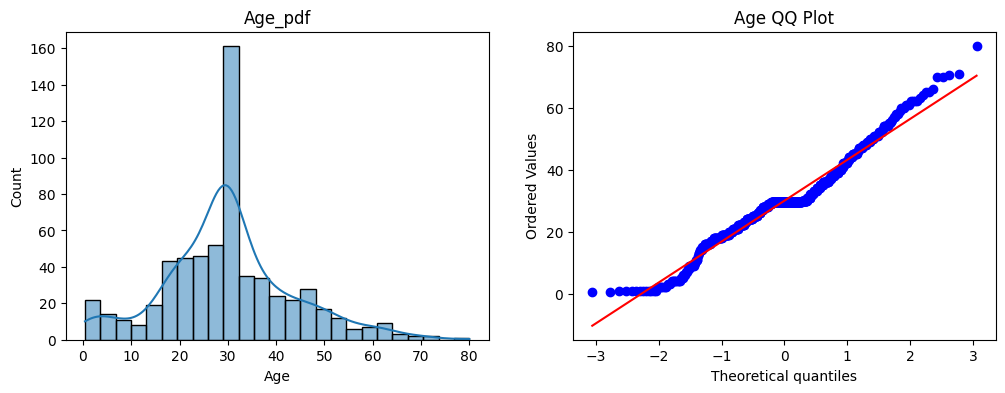

In [9]:
plt.figure(figsize = (12,4))
plt.subplot(121) # 121 means , 1 for rows , 2 for coulmns and 1 again for position left or right
sns.histplot(X_train['Age'] , kde=True)
plt.title('Age_pdf')

plt.subplot(122)
stats.probplot(X_train['Age'] , dist='norm' , plot=plt)
plt.title('Age QQ Plot')


plt.show()

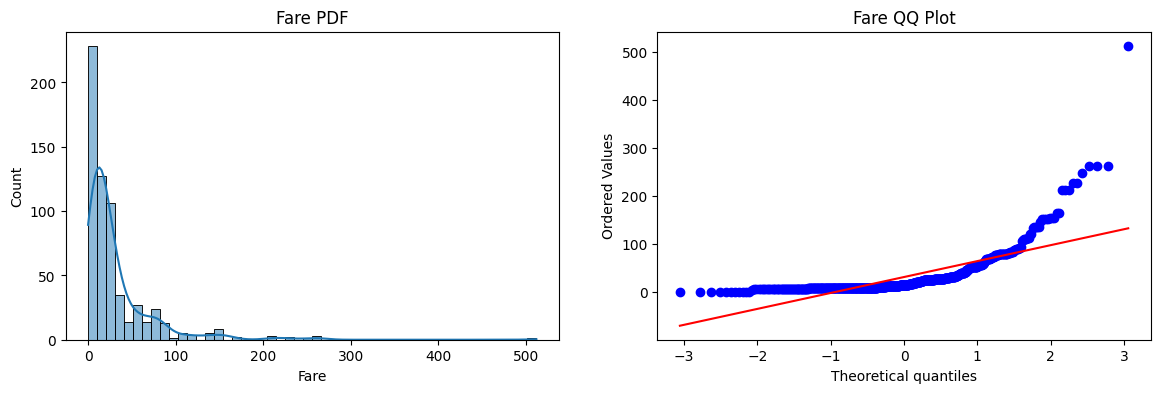

In [10]:
fig , axes = plt.subplots(nrows=1 , ncols = 2 , figsize=(14,4))
sns.histplot(X_train['Fare'] , kde=True , ax=axes[0])
axes[0].set_title('Fare PDF')

stats.probplot(X_train['Fare'] , dist = 'norm' , plot = axes[1])
axes[1].set_title('Fare QQ Plot')

plt.show()

#Right skewed

In [11]:
clf = LogisticRegression()
clf1 = DecisionTreeClassifier()

In [17]:
clf.fit(X_train , y_train)
clf1.fit(X_train , y_train)

y_pred = clf.predict(X_test)
y_pred1 = clf1.predict(X_test)

print("accuracy score LR" , accuracy_score(y_test,y_pred))
print("accuracy score DT" , accuracy_score(y_test , y_pred1))

accuracy score LR 0.6753731343283582
accuracy score DT 0.6231343283582089


In [18]:
trf = FunctionTransformer(func = np.log1p) #np.logp and np.log1p has one difference that np.log1p adds 1 to values as log0 is undefined

In [19]:
X_train_transformed = trf.fit_transform(X_train)
X_test_transformed = trf.transform(X_test)

In [20]:
clf.fit(X_train_transformed , y_train)
clf1.fit(X_train_transformed , y_train)

y_pred = clf.predict(X_test_transformed)
y_pred1 = clf1.predict(X_test_transformed)

print("accuracy score LR" , accuracy_score(y_test,y_pred))
print("accuracy score DT" , accuracy_score(y_test , y_pred1))

#decision tree dont get much impact but logistic regression did but to cross verify we use cross val

accuracy score LR 0.6977611940298507
accuracy score DT 0.6194029850746269


In [24]:
X_transformed = trf.fit_transform(X_train)

print("LR" , np.mean(cross_val_score(clf , X_transformed , y_train , scoring = 'accuracy' , cv=10)))
print("DT" , np.mean(cross_val_score(clf1 , X_transformed , y_train , scoring = 'accuracy' , cv=10)))

LR 0.6725038402457758
DT 0.6341525857654889


Text(0.5, 1.0, 'Fare after log')

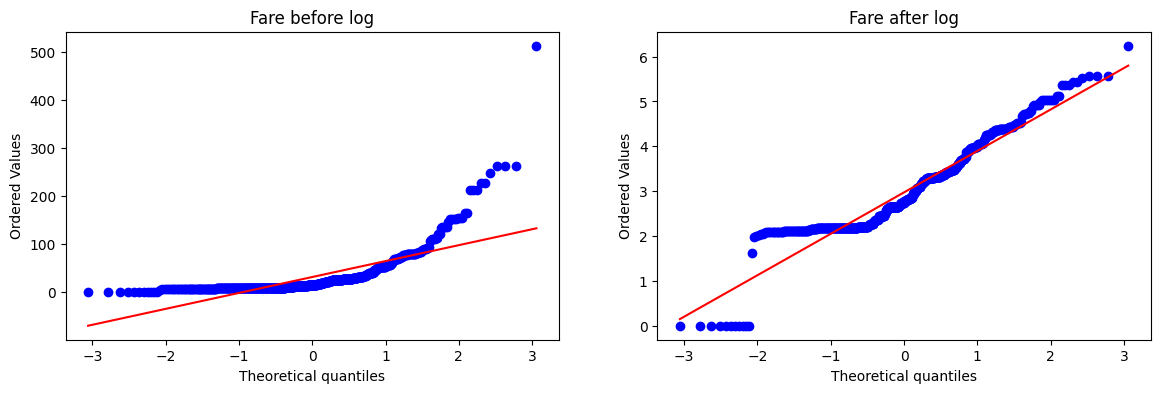

In [ ]:
plt.figure(figsize = (14,4))

plt.subplot(121)
stats.probplot(X_train['Fare'] , dist='norm' , plot=plt)
plt.title('Fare before log')

plt.subplot(122)
stats.probplot(X_train_transformed['Fare'] , dist='norm' , plot=plt)
plt.title('Fare after log')

#fare on track

Text(0.5, 1.0, 'Age after log')

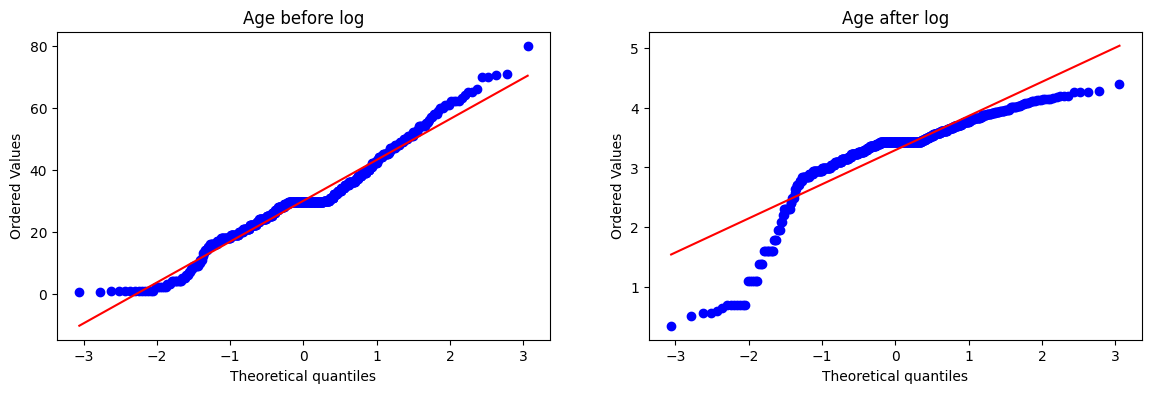

In [ ]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(X_train['Age'] , dist='norm' , plot=plt)
plt.title('Age before log')

plt.subplot(122)
stats.probplot(X_train_transformed['Age'] , dist='norm' , plot=plt)
plt.title('Age after log')

#age was already good and we used log which helps in right skewed

## Other Transforms ##

**Reciprocal transform**
smaller to larger and larger to smaller conversion of data

**square transform**
left skewed

**Square root transformed**